In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
!pip install wfdb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 4.3 MB/s eta 0:00:00


In [3]:
import numpy as np
import wfdb
import matplotlib.pyplot as plt

In [4]:
BEAT_SYMBOLS = set("NLRBAaJSVrFejnE/fQ?")

In [5]:
def charger_ecg(nom, duree_s=10, voie=0):
    fin = None if duree_s is None else int(duree_s * 360)
    record = wfdb.rdrecord(nom, pn_dir='mitdb', sampto=fin)
    annot = wfdb.rdann(nom, 'atr', pn_dir='mitdb', sampto=fin)

    x = record.p_signal[:, voie]
    fs = record.fs

    garder = [i for i, s in enumerate(annot.symbol) if s in BEAT_SYMBOLS]
    pos = annot.sample[garder]
    types = [annot.symbol[i] for i in garder]
    return x, fs, pos, types

In [6]:
def ms_vers_echantillons(duree_ms, fs):
    n = int(round(duree_ms / 1000 * fs))
    n = max(n, 1)
    return n if n % 2 == 1 else n + 1

fs = 360 Hz | durée = 10.0 s
nombre de battements annotés : 13
200 ms = 73 échantillons
16 ms  = 7 échantillons


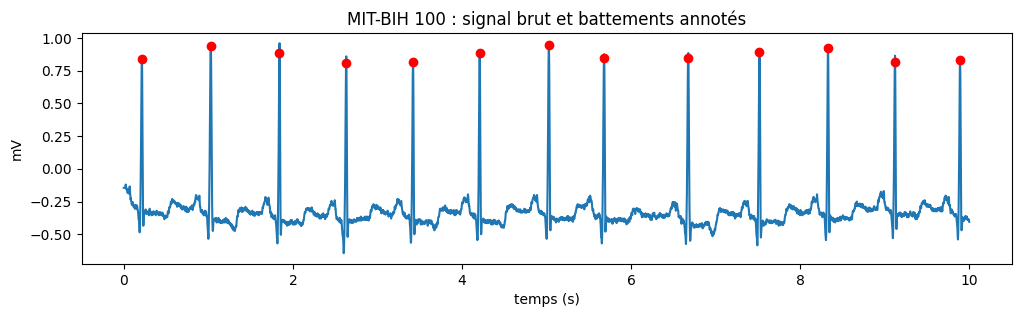

In [7]:
x, fs, pos, types = charger_ecg('100', duree_s=10)
t = np.arange(len(x)) / fs

print("fs =", fs, "Hz | durée =", len(x) / fs, "s")
print("nombre de battements annotés :", len(pos))
print("200 ms =", ms_vers_echantillons(200, fs), "échantillons")
print("16 ms  =", ms_vers_echantillons(16, fs), "échantillons")

plt.figure(figsize=(12, 3))
plt.plot(t, x)
plt.plot(t[pos], x[pos], 'ro')
plt.xlabel("temps (s)"); plt.ylabel("mV")
plt.title("MIT-BIH 100 : signal brut et battements annotés")
plt.show()

In [8]:
def erosion(x, n):
    r = n // 2
    xp = np.pad(x, r, mode='edge')
    out = np.empty_like(x)
    for i in range(len(x)):
        out[i] = xp[i:i + n].min()
    return out

In [9]:
def dilatation(x, n):
    r = n // 2
    xp = np.pad(x, r, mode='edge')
    out = np.empty_like(x)
    for i in range(len(x)):
        out[i] = xp[i:i + n].max()
    return out

signal     : [0. 0. 5. 0. 0. 0. 3. 3. 3. 3. 3. 0. 0. 0.]
érosion    : [0. 0. 0. 0. 0. 0. 0. 3. 3. 3. 0. 0. 0. 0.]
dilatation : [0. 5. 5. 5. 0. 3. 3. 3. 3. 3. 3. 3. 0. 0.]


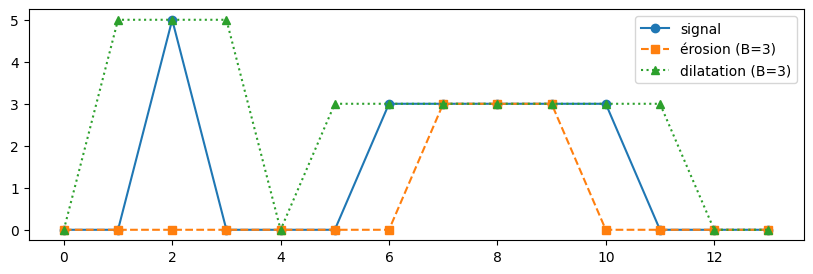

In [10]:
s = np.array([0, 0, 5, 0, 0, 0, 3, 3, 3, 3, 3, 0, 0, 0], dtype=float)

print("signal     :", s)
print("érosion    :", erosion(s, 3))
print("dilatation :", dilatation(s, 3))

plt.figure(figsize=(10, 3))
plt.plot(s, 'o-', label="signal")
plt.plot(erosion(s, 3), 's--', label="érosion (B=3)")
plt.plot(dilatation(s, 3), '^:', label="dilatation (B=3)")
plt.legend(); plt.show()

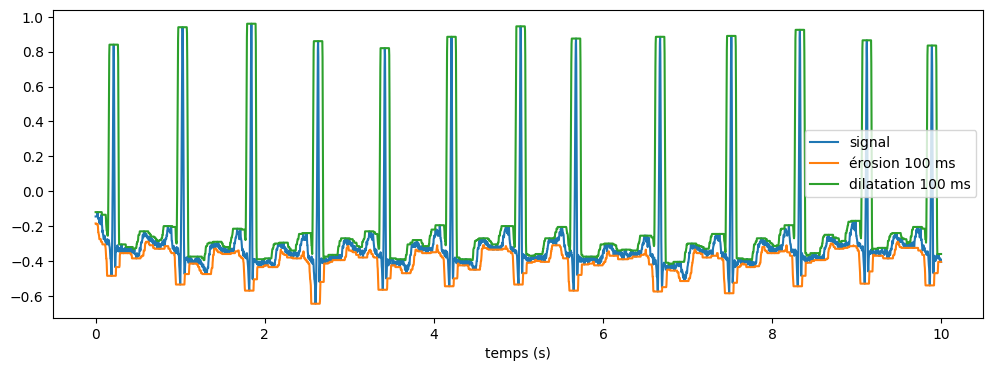

In [11]:
n = ms_vers_echantillons(100, fs)
ero = erosion(x, n)
dil = dilatation(x, n)

plt.figure(figsize=(12, 4))
plt.plot(t, x, label="signal")
plt.plot(t, ero, label="érosion 100 ms")
plt.plot(t, dil, label="dilatation 100 ms")
plt.xlabel("temps (s)"); plt.legend(); plt.show()